# A non-stationary field

A field is rarely the same everywhere. Soil contamination differs between an industrial zone and a
park, rainfall between the coast and the mountains, grades between two geological domains. Questions
about such fields are often about probabilities, the chance that the value at a place exceeds a limit.
Indicator kriging answers them threshold by threshold, with answers that need not fit together into a
law. Here we build a field with two halves of different behaviour and compare the probabilities the
ensemble gives with those of indicator kriging.

## Learning goals

- What the order relations of a cumulative distribution are, and why they matter.
- How the ensemble's members give, at every location, a law that always satisfies them.
- How indicator kriging, kriging one threshold at a time, breaks them, and how often.
- How the two compare on the truth, once indicator kriging is corrected.

*Do the probabilities of an estimate add up to a law?*

## The idea

The cumulative distribution $F(t) = P(Z \le t)$ of a value has to lie between 0 and 1 and grow with the
threshold $t$. These are its **order relations**. A probability of exceeding 20 above the probability of
exceeding 10 is not a law. Nor is an interval of thresholds with negative probability.

**Indicator kriging** turns each threshold into a variable of zeros and ones, $1\{Z \le t\}$, fits a
variogram to it and kriges it. Each threshold is kriged on its own, with weights that can be negative,
so nothing ties the answers together. The theory Spatialize rests on proves that indicator kriging can violate the order relations, and studies a field
with two halves where it does so over much of the map ([Estimating a law, not a map](https://spatialize.readthedocs.io/en/latest/theory/problem.html)).

The ensemble's members are values, so at each location their **empirical distribution** is a law by
construction, whatever thresholds we read it at. A drawing decoder keeps the dispersion of the data
within each cell, which makes that law spread as the data do.

## Step by step

### Two halves

The field is a Voronoi block-mark field with 60 cells on the unit square. Cells whose centre lies in the
left half take a Gaussian value of standard deviation 0.5, centred on 0. Those in the right half take a
lognormal value, positive and skewed, with a long right tail. We draw 400 samples at random.

thresholds [-0.28  0.11  0.32  0.59  2.23]


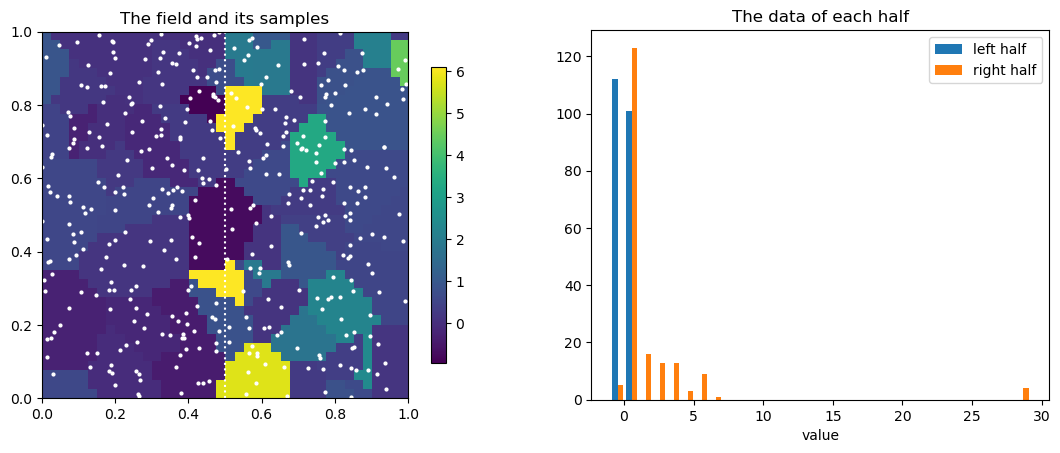

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pykrige.ok import OrdinaryKriging

import spatialize
from spatialize.gs.esi import esi_nongriddata, esi_pareto_hparams_search
import spatialize.gs.esi.scoring as sc

spatialize.session.set(empty_cells="coarsen", progress=False)
warnings.filterwarnings("ignore", module="pykrige")

m = 40
grid = (np.arange(m) + 0.5) / m
xi = np.stack(np.meshgrid(grid, grid), -1).reshape(-1, 2)          # maps are [y, x]

def halves(seed, n_cells=60, n_samples=400):
    rng = np.random.default_rng(seed)
    nuclei = rng.random((n_cells, 2))
    marks = np.where(nuclei[:, 0] < 0.5, rng.normal(0, 0.5, n_cells), rng.lognormal(0, 1.1, n_cells))
    value = lambda x: marks[np.argmin(((x[:, None, :] - nuclei[None]) ** 2).sum(-1), axis=1)]
    points = rng.random((n_samples, 2))
    return points, value(points), value(xi)

points, values, truth = halves(0)
thresholds = np.quantile(values, [0.1, 0.3, 0.5, 0.7, 0.9])
print("thresholds", np.round(thresholds, 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
im = axes[0].imshow(truth.reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="viridis", vmax=np.quantile(truth, 0.98))
axes[0].scatter(points[:, 0], points[:, 1], s=4, c="white")
axes[0].axvline(0.5, color="white", ls=":")
axes[0].set_title("The field and its samples")
fig.colorbar(im, ax=axes[0], shrink=0.8)
left = points[:, 0] < 0.5
axes[1].hist([values[left], values[~left]], bins=30, label=["left half", "right half"])
axes[1].set_xlabel("value"); axes[1].legend()
axes[1].set_title("The data of each half")
plt.show()

The left half varies little around zero, positive and negative. The right half is positive, mostly
small, with a few large cells. A single variogram, or a single law, describes neither half well.

### Choosing the ensemble

The question is about probabilities, so the ensemble is chosen by how well its law predicts, not by its
map. The Pareto search scores each candidate by the CRPS, a score of the whole law, each sample left out
in turn, and reads the granularity at the knee. The candidates are the five probabilistic decoders, the
uniform draw and the weighted draws of IDW, the kriging decoder, adaptive IDW and sharpened IDW, each on
Mondrian and on Voronoi partitions.

The truth takes no part in the choice. Beside each candidate's CRPS we print its Brier score against the
truth only to see whether the cross-validation ranks the candidates as the truth would. The Brier score
is the mean squared difference between the probability that the value lies at or below a threshold and
whether it does, averaged over the five thresholds, the deciles 1, 3, 5, 7 and 9 of the data. Lower is
better for both.

In [2]:
def spherical(h, c0, c, a):
    return c0 + c * np.where(h < a, 1.5 * h / a - 0.5 * (h / a) ** 3, 1.0)

def fitted_variogram(points, values):
    i, j = np.triu_indices(len(points), 1)
    dist = np.hypot(*(points[i] - points[j]).T)
    half_sq = 0.5 * (values[i] - values[j]) ** 2
    bins = np.digitize(dist, np.linspace(0, 0.6, 16))
    h = np.array([dist[bins == b].mean() for b in range(1, 16)])
    g = np.array([half_sq[bins == b].mean() for b in range(1, 16)])
    (c0, c, a), _ = curve_fit(spherical, h, g, p0=[0.1 * g.max() + 1e-6, g.max() + 1e-6, 0.2],
                              bounds=([0, 1e-6, 0.01], [np.inf, np.inf, 2]))
    return c0, c, a

def cumulative(members, thresholds):
    return np.stack([(members <= t).mean(axis=1) for t in thresholds], axis=1)

def brier(cdf, truth, thresholds):
    observed = np.stack([(truth <= t).astype(float) for t in thresholds], axis=1)
    return np.mean((cdf - observed) ** 2)

def candidates(points, values):
    c0, c, a = fitted_variogram(points, values)
    return {"draw": {}, "wdraw_idw": dict(exponent=[2.0]), "wdraw_adaptiveidw": {}, "wdraw_sharpidw": {},
            "wdraw_kriging": dict(model=["spherical"], nugget=[c0], range=[a], sill=[c0 + c])}

def chosen_ensemble(points, values, decoder, p_process, grid):
    knee = esi_pareto_hparams_search(points, values, local_interpolator=decoder, p_process=p_process, n_partitions=[100],
                                     alpha=[0.5, 0.6, 0.7, 0.8, 0.9, 0.95], k="loo", scoring="crps", seed=0,
                                     **grid).best_result(strategy="knee")
    members = esi_nongriddata(points, values, xi, local_interpolator=decoder, p_process=p_process, alpha=knee["alpha"],
                              n_partitions=200, seed=0, **{key: knee[key] for key in grid}).esi_samples()
    return knee, members

rows, ensembles = {}, {}
for p_process in ("mondrian", "voronoi"):
    for decoder, decoder_grid in candidates(points, values).items():
        knee, mem = chosen_ensemble(points, values, decoder, p_process, decoder_grid)
        ensembles[(p_process, decoder)] = mem
        rows[f"{p_process}, {decoder}"] = {"alpha": knee["alpha"], "leave-one-out CRPS": knee["decoder_error"],
                                           "Brier against the truth": brier(cumulative(mem, thresholds), truth, thresholds)}
table = pd.DataFrame(rows).T.sort_values("leave-one-out CRPS")
best_process, best_decoder = table.index[0].split(", ")
members = ensembles[(best_process, best_decoder)]
ensemble_cdf = cumulative(members, thresholds)
print(f"chosen by the CRPS, {best_decoder} on {best_process} partitions; rank agreement between the two scores "
      f"{table.corr(method='spearman').loc['leave-one-out CRPS', 'Brier against the truth']:.2f}")
table.round(4)

chosen by the CRPS, wdraw_sharpidw on mondrian partitions; rank agreement between the two scores 0.93


,alpha,leave-one-out CRPS,Brier against the truth
"mondrian, wdraw_sharpidw",0.90,0.2243,0.0371
"mondrian, wdraw_adaptiveidw",0.90,0.2285,0.0373
"voronoi, wdraw_adaptiveidw",0.70,0.2325,0.0373
"voronoi, wdraw_sharpidw",0.70,0.2419,0.0375
"voronoi, wdraw_kriging",0.70,0.2510,0.0382
"voronoi, wdraw_idw",0.90,0.2556,0.0396
"voronoi, draw",0.95,0.2802,0.0458
"mondrian, wdraw_kriging",0.95,0.2811,0.0392
"mondrian, wdraw_idw",0.95,0.2989,0.0412
"mondrian, draw",0.95,0.4580,0.0701


The weighted draws of adaptive and sharpened IDW lead by the CRPS on both kinds of partition, while the
uniform draw trails. The CRPS orders the ten candidates almost as the truth does, a rank agreement of
0.93. The search picks the weighted draw of sharpened IDW on Mondrian partitions, which also has the
lowest Brier score against the truth, 0.037. The uniform draw on Mondrian partitions comes last by both
scores, with nearly twice the Brier score of the others.

### Indicator kriging

For each threshold, the indicator $1\{Z \le t\}$ of the data gets a spherical variogram fitted to its
experimental variogram, then ordinary kriging on the grid, in the usual way.

In [3]:
def ordinary_kriging(points, values):
    c0, c, a = fitted_variogram(points, values)
    ok = OrdinaryKriging(points[:, 0], points[:, 1], values, variogram_model="spherical",
                         variogram_parameters={"sill": c0 + c, "range": a, "nugget": c0})
    return ok.execute("points", xi[:, 0], xi[:, 1])[0].data

def indicator_kriging(points, values, thresholds):
    return np.stack([ordinary_kriging(points, (values <= t).astype(float)) for t in thresholds], axis=1)

def order_relations(cdf):
    return {"locations not rising with the threshold": np.mean(np.any(np.diff(cdf, axis=1) < 0, axis=1)),
            "locations outside [0, 1]": np.mean(np.any((cdf < 0) | (cdf > 1), axis=1)),
            "most negative interval probability": np.diff(np.c_[np.zeros(len(cdf)), cdf], axis=1).min()}

ik_cdf = indicator_kriging(points, values, thresholds)
pd.DataFrame({"ensemble": order_relations(ensemble_cdf), "indicator kriging": order_relations(ik_cdf)}).T.round(3)

,locations not rising with the threshold,"locations outside [0, 1]",most negative interval probability
ensemble,0.000,0.000,0.000
indicator kriging,0.756,0.758,-0.462


Indicator kriging breaks the order relations at most locations. Its cumulative probability falls between
two thresholds at 76 % of the grid and leaves [0, 1] at 76 %, with an interval of thresholds whose
probability reaches −0.46. The ensemble breaks them nowhere.

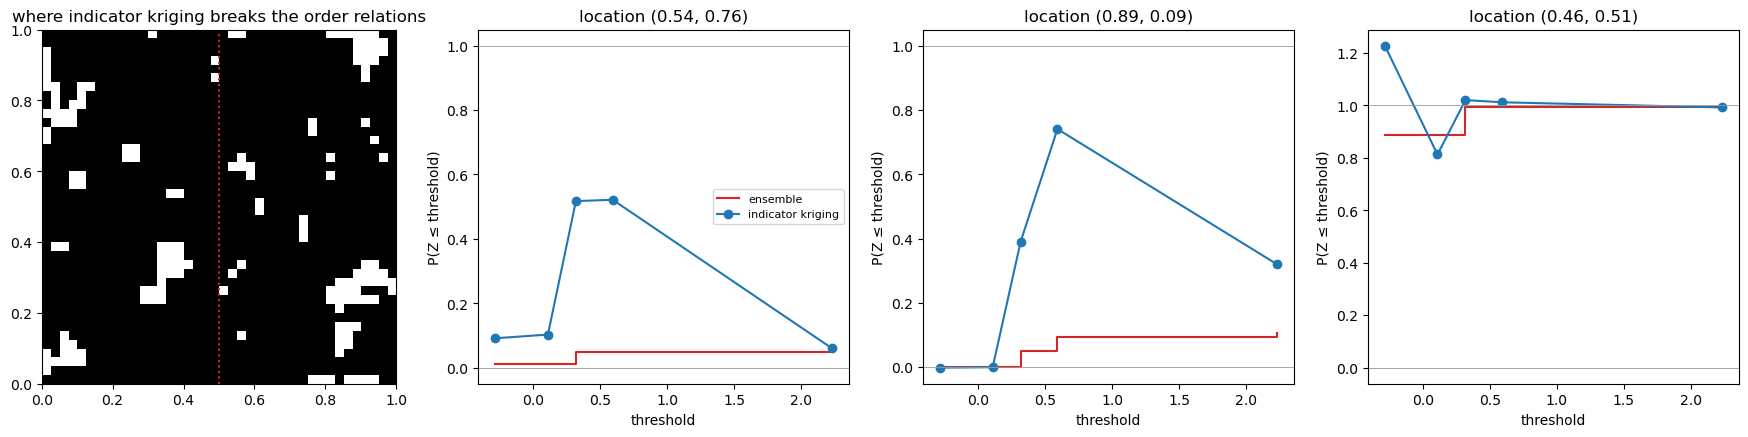

In [4]:
broken = np.any(np.diff(ik_cdf, axis=1) < 0, axis=1) | np.any((ik_cdf < 0) | (ik_cdf > 1), axis=1)
worst = np.argsort(np.diff(np.c_[np.zeros(len(ik_cdf)), ik_cdf], axis=1).min(axis=1))[:3]
fig, axes = plt.subplots(1, 4, figsize=(22, 4.6))
axes[0].imshow(broken.reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="Greys")
axes[0].axvline(0.5, color="C3", ls=":")
axes[0].set_title("where indicator kriging breaks the order relations")
for ax, k in zip(axes[1:], worst):
    ax.step(thresholds, ensemble_cdf[k], where="post", color="C3", label="ensemble")
    ax.plot(thresholds, ik_cdf[k], "o-", color="C0", label="indicator kriging")
    ax.axhline(0, color="0.6", lw=0.6); ax.axhline(1, color="0.6", lw=0.6)
    ax.set_title(f"location ({xi[k, 0]:.2f}, {xi[k, 1]:.2f})")
    ax.set_xlabel("threshold"); ax.set_ylabel("P(Z ≤ threshold)")
axes[1].legend(fontsize=8)
plt.show()

Black marks the locations where indicator kriging breaks the order relations, most of the map on both
halves. At the three locations of its most negative interval probability, its cumulative probability
rises and then falls, or starts above one, while the ensemble's steps rise from threshold to threshold.

### The maps

At the median threshold, the third, we compare the truth's indicator, whether the value lies at or below
the threshold, with the probability each method gives. Indicator kriging's raw values are shown on a
scale that extends past [0, 1], so the impossible ones show. The estimated value, the mean of the
members against ordinary kriging of the data, completes the picture.

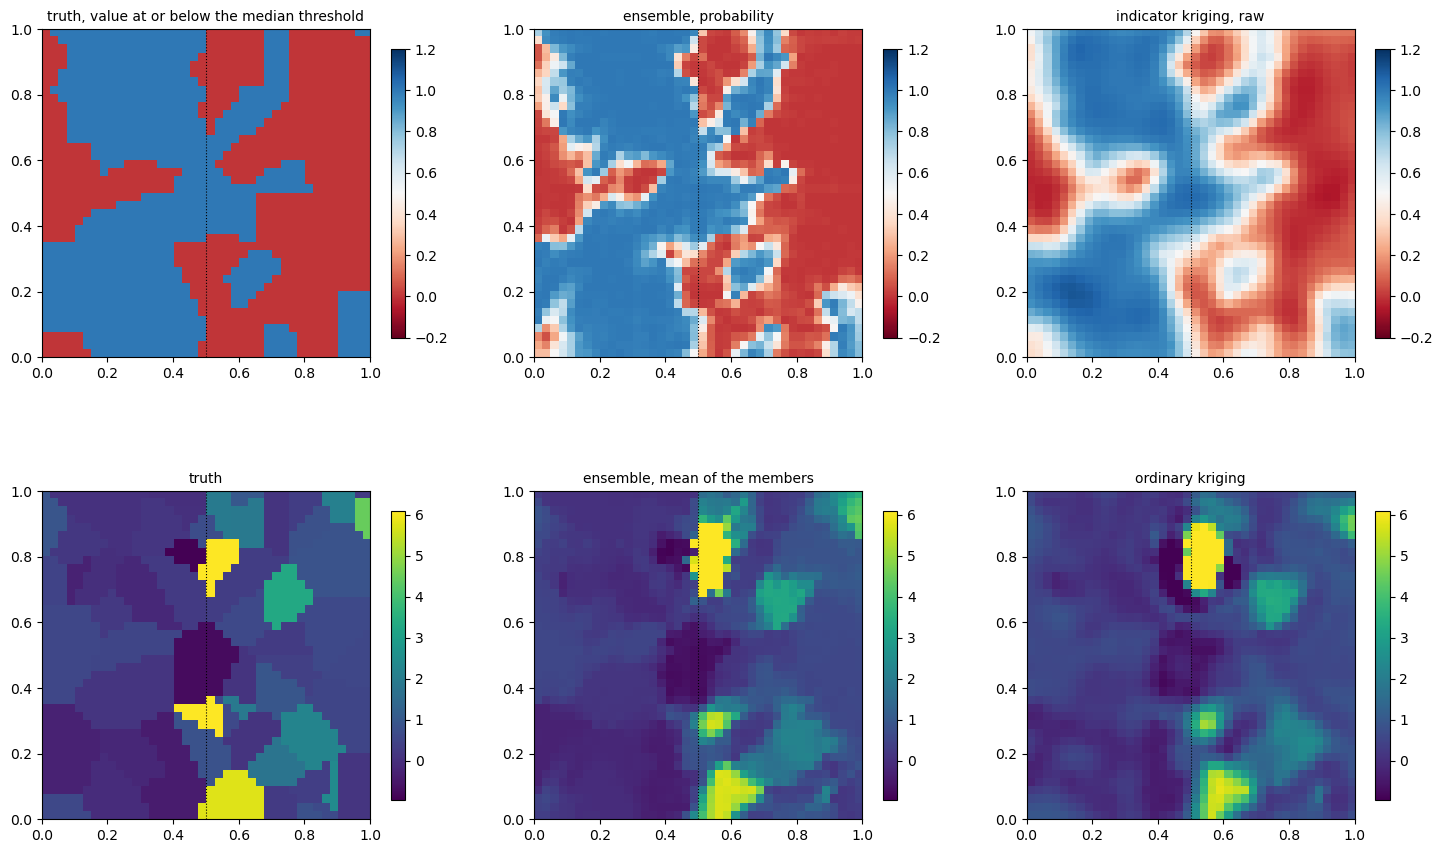

indicator kriging at the median threshold, below 0 at 8.1% and above 1 at 13.2% of the grid


In [5]:
k = 2
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
panels = [("truth, value at or below the median threshold", (truth <= thresholds[k]).astype(float), "RdBu", (-0.2, 1.2)),
          ("ensemble, probability", ensemble_cdf[:, k], "RdBu", (-0.2, 1.2)),
          ("indicator kriging, raw", ik_cdf[:, k], "RdBu", (-0.2, 1.2)),
          ("truth", truth, "viridis", (truth.min(), np.quantile(truth, 0.98))),
          ("ensemble, mean of the members", members.mean(axis=1), "viridis", (truth.min(), np.quantile(truth, 0.98))),
          ("ordinary kriging", ordinary_kriging(points, values), "viridis", (truth.min(), np.quantile(truth, 0.98)))]
for ax, (title, z, cmap, (lo, hi)) in zip(axes.ravel(), panels):
    im = ax.imshow(z.reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap=cmap, vmin=lo, vmax=hi)
    ax.axvline(0.5, color="black", ls=":", lw=0.8)
    ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.75)
plt.show()
print(f"indicator kriging at the median threshold, below 0 at {np.mean(ik_cdf[:, k] < 0):.1%} "
      f"and above 1 at {np.mean(ik_cdf[:, k] > 1):.1%} of the grid")

The ensemble's probability follows the truth's indicator closely, blue where the value lies at or below
the threshold, red where it lies above, with sharp edges along the boundaries of the cells. Indicator
kriging draws the same regions as smooth blobs, its deepest colours lying outside [0, 1], below 0 at 8 %
of the grid and above 1 at 13 %. Among the estimated values, ordinary kriging digs a dark ring below
the surrounding values around the large cell near (0.5, 0.8), which the mean of the members does not.

### Against the truth

In practice indicator kriging is corrected after the fact, its probabilities clipped to [0, 1] and then
forced to rise with the threshold. Once corrected, both sets of probabilities can be judged against the
truth by the Brier score, the mean squared difference between the probability that the value lies at or
below a threshold and whether it does, averaged over the five thresholds. Lower is better.

In [6]:
def corrected(cdf):
    return np.maximum.accumulate(np.clip(cdf, 0, 1), axis=1)

pd.Series({f"ensemble, {best_decoder} on {best_process}": brier(ensemble_cdf, truth, thresholds),
           "indicator kriging, corrected": brier(corrected(ik_cdf), truth, thresholds)},
          name="Brier score").round(4).to_frame()

,Brier score
"ensemble, wdraw_sharpidw on mondrian",0.0371
"indicator kriging, corrected",0.0429


Even corrected, indicator kriging scores worse than the chosen ensemble, 0.043 against 0.037, a Brier
score about 16 % larger. The ensemble's probabilities, the more accurate ones, form a law at every location without any
correction.

### Five fields

We repeat the comparison on five fields with the same recipe, the decoder and the partitions chosen
above, the Pareto search choosing the granularity of each field by the CRPS.

In [7]:
rows, stored = {}, {}
for seed in range(5):
    p, v, t = halves(seed)
    th = np.quantile(v, [0.1, 0.3, 0.5, 0.7, 0.9])
    _, mem = chosen_ensemble(p, v, best_decoder, best_process, candidates(p, v)[best_decoder])
    e_cdf = cumulative(mem, th)
    i_cdf = indicator_kriging(p, v, th)
    stored[seed] = (e_cdf, corrected(i_cdf), t, th)
    rows[f"field {seed}"] = {"ensemble, broken locations": order_relations(e_cdf)["locations not rising with the threshold"],
                             "indicator kriging, broken locations": np.mean(np.any(np.diff(i_cdf, axis=1) < 0, axis=1)
                                                                            | np.any((i_cdf < 0) | (i_cdf > 1), axis=1)),
                             "Brier, ensemble": brier(e_cdf, t, th),
                             "Brier, indicator kriging corrected": brier(corrected(i_cdf), t, th)}
pd.DataFrame(rows).T.round(4)

,"ensemble, broken locations","indicator kriging, broken locations","Brier, ensemble","Brier, indicator kriging corrected"
field 0,0.0,0.9050,0.0371,0.0429
field 1,0.0,0.9681,0.0381,0.0419
field 2,0.0,0.9275,0.0404,0.0437
field 3,0.0,0.9431,0.0426,0.0425
field 4,0.0,0.8919,0.0390,0.0437


On every field indicator kriging breaks the order relations at 89 % to 97 % of the locations, the
ensemble at none. With the same recipe, the ensemble has the lower Brier score on four fields, by 8 % to
14 %, and ties on the fifth, 0.0426 against 0.0425.

### The doubt along the boundaries

At a single threshold the probability is most uncertain at one half, the white of the maps above, where
the binary entropy $-p \log_2 p - (1 - p) \log_2 (1 - p)$ reaches its maximum of one bit. Both methods
whiten the boundaries of the truth's indicator. Indicator kriging smooths them, so its white bands are
wider. We map the entropy of each method at the median threshold, with the true boundary drawn over it,
then measure where the doubt lies and whether it is warranted.

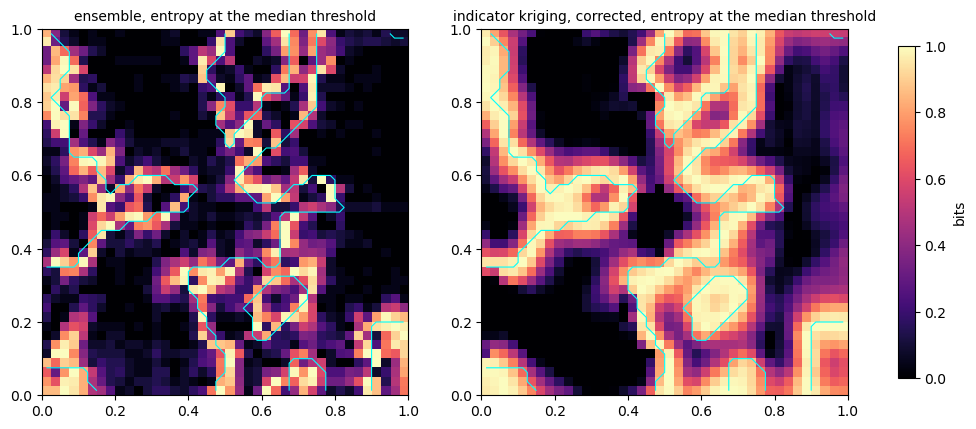

,share of the map with p between 0.3 and 0.7,entropy on the true boundaries,entropy away from them,share truly below where p is between 0.4 and 0.6
ensemble,0.086,0.582,0.036,0.414
"indicator kriging, corrected",0.214,0.850,0.073,0.377
"ensemble, five fields",0.095,0.627,0.044,0.476
"indicator kriging, corrected, five fields",0.195,0.846,0.076,0.409


In [8]:
from scipy.ndimage import distance_transform_edt

def entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

def boundary(indicator):
    edge = np.zeros_like(indicator)
    for a, b, shift in ((indicator[:, 1:], indicator[:, :-1], 1), (indicator[1:, :], indicator[:-1, :], 0)):
        differs = a != b
        if shift:
            edge[:, 1:] |= differs; edge[:, :-1] |= differs
        else:
            edge[1:, :] |= differs; edge[:-1, :] |= differs
    return edge

def doubt(p, truth, threshold):
    below = truth <= threshold
    edge = boundary(below.reshape(m, m))
    far = (distance_transform_edt(~edge) > 3).ravel()
    edge = edge.ravel()
    middle = (p > 0.4) & (p < 0.6)
    return {"share of the map with p between 0.3 and 0.7": np.mean((p > 0.3) & (p < 0.7)),
            "entropy on the true boundaries": entropy(p)[edge].mean(),
            "entropy away from them": entropy(p)[far].mean(),
            "share truly below where p is between 0.4 and 0.6": below[middle].mean()}

k = 2
methods = {f"ensemble": ensemble_cdf[:, k], "indicator kriging, corrected": corrected(ik_cdf)[:, k]}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, (name, p) in zip(axes, methods.items()):
    im = ax.imshow(entropy(p).reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="magma", vmin=0, vmax=1)
    ax.contour(grid, grid, (truth <= thresholds[k]).reshape(m, m).astype(float), levels=[0.5], colors="cyan", linewidths=0.8)
    ax.set_title(f"{name}, entropy at the median threshold", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8, label="bits")
plt.show()

table = {name: doubt(p, truth, thresholds[k]) for name, p in methods.items()}
for name, column in (("ensemble", 0), ("indicator kriging, corrected", 1)):
    table[f"{name}, five fields"] = pd.DataFrame([doubt(stored[seed][column][:, 2], stored[seed][2], stored[seed][3][2])
                                                  for seed in stored]).mean().to_dict()
pd.DataFrame(table).T.round(3)

Both entropy maps light up along the true boundaries. Indicator kriging's bands are wide and smooth.
Over five fields, a fifth of its map carries a probability between 0.3 and 0.7, against a tenth of the
ensemble's. Its entropy is higher on the boundaries, 0.85 bits against 0.63, and nearly twice the
ensemble's away from them. The extra doubt is not warranted. Where indicator kriging states a probability
between 0.4 and 0.6, the truth lies below the threshold 41 % of the time over five fields, against 48 %
for the ensemble.

A calibration diagram checks every probability, not only those near one half. Over the five fields and
the five thresholds, the locations are grouped by the probability each method states, each group's stated probability set
against how often the truth lies at or below the threshold. A calibrated
method stays on the diagonal.

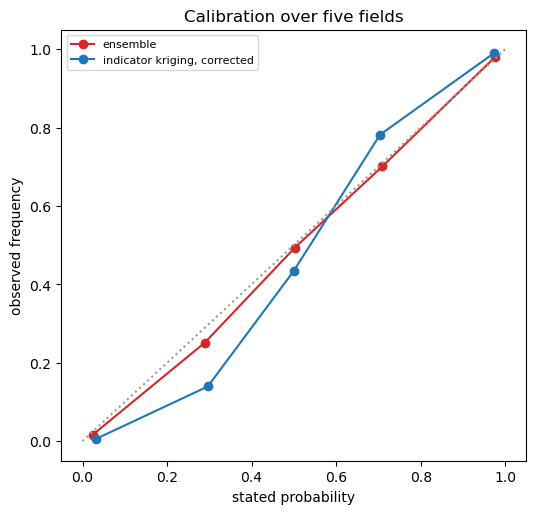

In [9]:
edges = np.linspace(0, 1, 6)
fig, ax = plt.subplots(figsize=(6, 5.6))
for column, (name, colour) in enumerate((("ensemble", "C3"), ("indicator kriging, corrected", "C0"))):
    stated = np.concatenate([stored[seed][column].ravel() for seed in stored])
    observed = np.concatenate([np.stack([(stored[seed][2] <= x) for x in stored[seed][3]], axis=1).ravel()
                               for seed in stored])
    group = np.digitize(stated, edges[1:-1])
    ax.plot([stated[group == g].mean() for g in range(5)], [observed[group == g].mean() for g in range(5)],
            "o-", color=colour, label=name)
ax.plot([0, 1], [0, 1], color="0.6", ls=":")
ax.set_xlabel("stated probability"); ax.set_ylabel("observed frequency")
ax.set_title("Calibration over five fields")
ax.legend(fontsize=8)
plt.show()

The ensemble stays on the diagonal. Indicator kriging bends away from it in the S of a method too
unsure of itself, its stated 0.3 coming true 14 % of the time and its 0.7 78 % of the time. Its smoothing
pulls the probabilities of settled locations towards one half, so its wide white bands record doubt the
data do not support. Clipping and sorting, which correct the order relations, leave that doubt in place.

## Pitfalls

- **An ensemble chosen for its map.** A granularity and a decoder chosen by the absolute error of the
  map can give a law that scores worse than corrected indicator kriging, as a first version of this
  tutorial found. Choose the ensemble for probabilities by a score of laws, the CRPS.
- **The law read from an averaging decoder.** Its members are too close together for the field, so its
  probabilities are too sharp. Read the law from a drawing decoder.
- **Thresholds beyond the data.** The members of a drawing decoder are data values, so the law at a
  location puts no probability above the largest datum or below the smallest. The chance of exceeding a
  level higher than every sample comes out as zero, whatever the field holds.
- **Too few partitions for a probability.** A probability is a share of the members, in steps of one
  over their number. At 0.5 with 200 partitions, a share moves by about 0.035 from one seed to another.
  Where a probability matters, use more partitions and compare seeds.
- **Wide white zones read as caution.** A wider band of probabilities near one half is not more prudent
  if those probabilities are not calibrated. Check the calibration before trusting the width of the doubt.
- **Cells across a change of regime.** A cell that straddles the boundary between the two halves holds
  data of both, so the law near the boundary blends the two halves. Read probabilities in that band with
  care, since the blend comes from the cells, not from the field.

## Try it yourself

1. Use eleven thresholds instead of five and count the broken locations again.
2. Choose the decoder and the granularity by the absolute error of the map (`scoring=sc.mae`) instead,
   and compare the Brier score.
3. Map the probability that the value exceeds the 9th decile, from the ensemble and from corrected
   indicator kriging.

## Next

- *The probabilistic decoders*, for the drawing decoders and the law they give.
- *Rain, an atom at zero*, for probabilities of a dry day.
- *Heavy tails*, for the right tail of a law like the right half's.
- The documentation's [The error of an ensemble](https://spatialize.readthedocs.io/en/latest/theory/error.html)
  (theory).